<a href="https://colab.research.google.com/github/nurfnick/Mathematical_Musings/blob/main/OnesDigitSquares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Exploring the Units (Ones) Digit of Squares
We will calculate the square of each integer from $1$ to $100$ and extract its last digit using the modulo operator `square % 10`.

In [15]:
import pandas as pd

# Create a list of numbers from 1 to 100
numbers = list(range(1, 101))

# Calculate their squares
squares = [n**2 for n in numbers]

# Extract the ones digit (units digit)
ones_digits = [sq % 10 for sq in squares]

# Create a DataFrame to display the results clearly
df = pd.DataFrame({
    'Number': numbers,
    'Square': squares,
    'Ones Digit': ones_digits
})

# Display the first 20 rows to observe the repeating pattern
display(df.head(20))

,Number,Square,Ones Digit
0,1,1,1
1,2,4,4
2,3,9,9
3,4,16,6
4,5,25,5
5,6,36,6
6,7,49,9
7,8,64,4
8,9,81,1
9,10,100,0


### Frequency of Each Ones Digit
Let's count how often each digit (0-9) appears as the ones digit of a square number.

In [16]:
frequency = df['Ones Digit'].value_counts().sort_index()
print("Frequency of each ones digit for squares up to 100^2:")
print(frequency)

Frequency of each ones digit for squares up to 100^2:
Ones Digit
0    10
1    20
4    20
5    10
6    20
9    20
Name: count, dtype: int64


### Exploring Squares in Base 7
In base 7, the units digit of any number $x^2$ is simply $(x^2) \pmod 7$. Let's calculate this for the first several numbers to reveal the pattern.

In [17]:
# In base 7, the pattern of the units digit repeats every 7 numbers
# Let's look at numbers from 1 to 21 to see the repetition clearly
numbers_b7 = list(range(1, 22))
squares_b7 = [n**2 for n in numbers_b7]
units_digit_b7 = [sq % 7 for sq in squares_b7]

# Create a table to show the repeating pattern
df_b7 = pd.DataFrame({
    'Number (Decimal)': numbers_b7,
    'Square (Decimal)': squares_b7,
    'Units Digit (Base 7)': units_digit_b7
})

display(df_b7)

,Number (Decimal),Square (Decimal),Units Digit (Base 7)
0,1,1,1
1,2,4,4
2,3,9,2
3,4,16,2
4,5,25,4
5,6,36,1
6,7,49,0
7,8,64,1
8,9,81,4
9,10,100,2


### The Base 7 Repeating Sequence
As we can see from the outputs, the units digit in base 7 follows a perfectly symmetrical repeating pattern:

**1, 4, 2, 2, 4, 1, 0**

Notice that:
- Just like in base 10, not all digits can be the last digit of a square. In base 7, a perfect square can only end in **0, 1, 2, or 4**.
- The digits **3, 5, and 6** never appear as the units digit of a square in base 7 (these are called quadratic non-residues modulo 7).

### Exploring Squares in Base 60
In any base $B$, the units digit of a squared number depends only on the units digit of the original number. Since there are only $B$ possible units digits ($0$ to $B-1$), the sequence of units digits for perfect squares must repeat with a period of $B$ (or a factor of $B$).

Let's calculate the units digit of squares in base 60: $x^2 \pmod{60}$.

In [18]:
# Calculate units digit in base 60 for numbers up to 150 to observe repetition
numbers_b60 = list(range(1, 151))
units_digit_b60 = [(n**2) % 60 for n in numbers_b60]

# Create a DataFrame
df_b60 = pd.DataFrame({
    'Number': numbers_b60,
    'Square': [n**2 for n in numbers_b60],
    'Units Digit (Base 60)': units_digit_b60
})

# Let's verify that the pattern repeats every 60 numbers
period_length = 60
is_periodic = all(units_digit_b60[i] == units_digit_b60[i + period_length] for i in range(len(units_digit_b60) - period_length))

print(f"Does the pattern repeat every 60 numbers? {is_periodic}")

# Find the set of all unique units digits in base 60
unique_units_b60 = sorted(list(set(units_digit_b60)))
print(f"\nThere are {len(unique_units_b60)} possible units digits in base 60 (out of 60 possible values):")
print(unique_units_b60)

# Display the first 65 entries to see the pattern and the start of its repetition
display(df_b60.head(65))

Does the pattern repeat every 60 numbers? True

There are 12 possible units digits in base 60 (out of 60 possible values):
[0, 1, 4, 9, 16, 21, 24, 25, 36, 40, 45, 49]


,Number,Square,Units Digit (Base 60)
0,1,1,1
1,2,4,4
2,3,9,9
3,4,16,16
4,5,25,25
...,...,...,...
60,61,3721,1
61,62,3844,4
62,63,3969,9
63,64,4096,16


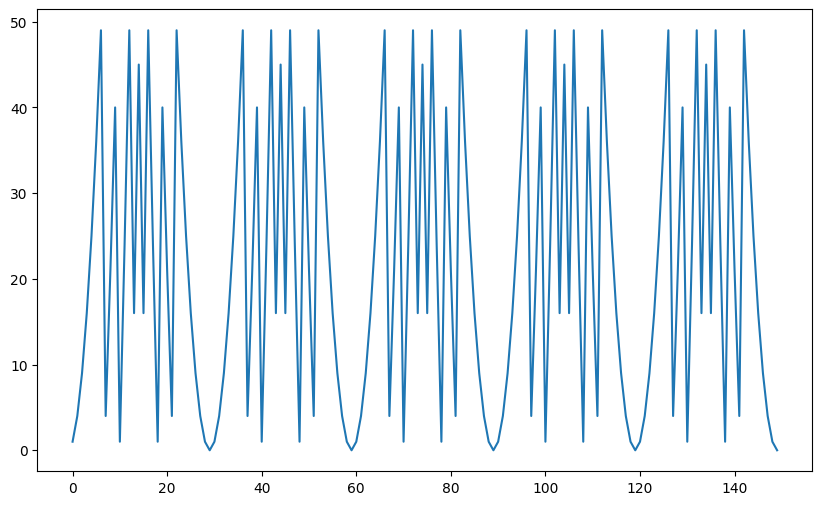

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(df_b60['Units Digit (Base 60)'])